# Ablation: weighting function for negatives in MyLoss (SC-InfoNCE)

`MyLoss` weights each in-batch pair by `W = rating / 5.0` (0 if the pair was never rated).
The positive (diagonal) term always keeps `W` as-is: `weighted_logit = s_ij + log(W)`.
This ablation only changes **how the negative (off-diagonal) weight is derived from `W`**:

| Variant | negative weight | formula plugged into `exp(s_ij) * weight` |
|---|---|---|
| `linear`    (yours, current MyLoss) | `1 - W`   | `e^{s_ij}(1-W_{ij})` |
| `recip`                              | `1 / W`   | `e^{s_ij}(1/W_{ij})` |
| `exp_linear`                         | `e^{1-W}` | `e^{s_ij}\,e^{(1-W_{ij})}` |
| `exp_recip`                          | `e^{1/W}` | `e^{s_ij}\,e^{(1/W_{ij})}` |

Everything else — backbone, data split, batch size, optimizer, LR schedule, temperature,
early stopping, seeds — is **identical** across the 4 runs (standard ablation practice:
change one component, hold everything else fixed, report mean ± std over multiple seeds).

`W` is clamped to `[EPS, 1]` before taking `1/W` (and before `log`) so unobserved pairs
(`W=0`) don't produce `inf`/`nan`. `EPS` is the only numerical safeguard added and is the
same for every variant, so it does not bias the comparison.

In [1]:
import os, math, random, time, copy
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

POS_THRESHOLD = 4
VAL_FRACTION = 0.2
SPLIT_SEED = 2026
EPS = 1e-2          # floor for W before 1/W and log(.)  -- same for every variant

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


In [2]:
# ═══════════════════════════════════════════════════════════════
# 1. DATA / SPLIT — identical to yahoo-earlystopping.ipynb
# ═══════════════════════════════════════════════════════════════
def load_yahoo():
    train_df = pd.read_csv(
        "/kaggle/input/datasets/limitiao/yahoor3/user.txt",
        header=None, names=["user_idx", "item_idx", "rating"])
    mar_df = pd.read_csv(
        "/kaggle/input/datasets/limitiao/yahoor3/random.txt",
        header=None, names=["user_idx", "item_idx", "rating"])

    num_users = int(max(train_df["user_idx"].max(), mar_df["user_idx"].max())) + 1
    num_items = int(max(train_df["item_idx"].max(), mar_df["item_idx"].max())) + 1

    for df in (train_df, mar_df):
        df["user_idx"] = df["user_idx"].astype(int)
        df["item_idx"] = df["item_idx"].astype(int)

    rng = np.random.default_rng(SPLIT_SEED)
    shuffled_idx = rng.permutation(len(mar_df))
    n_val = int(len(mar_df) * VAL_FRACTION)
    val_df = mar_df.iloc[shuffled_idx[:n_val]].reset_index(drop=True)
    test_df = mar_df.iloc[shuffled_idx[n_val:]].reset_index(drop=True)

    user_feat_tensor = torch.zeros(num_users, 0, dtype=torch.float32)
    item_feat_tensor = torch.zeros(num_items, 0, dtype=torch.float32)

    return dict(train_df=train_df, val_df=val_df, test_df=test_df,
                num_users=num_users, num_items=num_items,
                user_feat_tensor=user_feat_tensor, item_feat_tensor=item_feat_tensor)


def make_ground_truth(split_df, pos_threshold=POS_THRESHOLD):
    pos_df = split_df[split_df["rating"] >= pos_threshold]
    ground_truth = defaultdict(set)
    for row in pos_df.itertuples():
        ground_truth[row.user_idx].add(row.item_idx)
    return dict(ground_truth)


def make_r_lookup(train_df, num_users, num_items):
    r_lookup = torch.zeros(num_users, num_items, dtype=torch.float32)
    uids_all = torch.tensor(train_df["user_idx"].values, dtype=torch.long)
    iids_all = torch.tensor(train_df["item_idx"].values, dtype=torch.long)
    rats_all = torch.tensor(train_df["rating"].values, dtype=torch.float32)
    r_lookup[uids_all, iids_all] = rats_all
    return r_lookup.to(DEVICE)


def make_user_seen(train_df):
    user_seen = defaultdict(set)
    for row in train_df.itertuples():
        user_seen[row.user_idx].add(row.item_idx)
    return user_seen


class CLIPDataset(Dataset):
    def __init__(self, train_df, user_feat_tensor, item_feat_tensor, pos_threshold=POS_THRESHOLD):
        pos_df = train_df[train_df["rating"] >= pos_threshold].copy()
        self.user_idxs = pos_df["user_idx"].values.astype(int)
        self.item_idxs = pos_df["item_idx"].values.astype(int)
        self.user_feats = user_feat_tensor
        self.item_feats = item_feat_tensor

    def __len__(self):
        return len(self.user_idxs)

    def __getitem__(self, idx):
        uid = int(self.user_idxs[idx])
        iid = int(self.item_idxs[idx])
        return {"uid": uid, "vid": iid,
                "user_feats": self.user_feats[uid],
                "movie_feats": self.item_feats[iid]}


In [3]:
# ═══════════════════════════════════════════════════════════════
# 2. SHARED ARCHITECTURE — identical to yahoo-earlystopping.ipynb
# ═══════════════════════════════════════════════════════════════
EMBED_DIM = 256
ID_EMB_DIM = 64
HIDDEN = (256, 128)


def make_tower(input_dim, hidden=HIDDEN, out_dim=EMBED_DIM):
    layers, in_d = [], input_dim
    for h in hidden:
        layers += [nn.Linear(in_d, h), nn.LayerNorm(h), nn.ReLU()]
        in_d = h
    layers.append(nn.Linear(in_d, out_dim))
    return nn.Sequential(*layers)


class TwoTowerEncoder(nn.Module):
    def __init__(self, num_users, num_items, user_feat_dim, item_feat_dim,
                 id_emb_dim=ID_EMB_DIM, hidden=HIDDEN, out_dim=EMBED_DIM):
        super().__init__()
        self.user_id_emb = nn.Embedding(num_users, id_emb_dim)
        self.movie_id_emb = nn.Embedding(num_items, id_emb_dim)
        self.user_tower = make_tower(user_feat_dim + id_emb_dim, hidden, out_dim)
        self.movie_tower = make_tower(item_feat_dim + id_emb_dim, hidden, out_dim)

    def encode_user(self, user_feats, uid):
        id_e = self.user_id_emb(uid)
        return F.normalize(self.user_tower(torch.cat([user_feats, id_e], dim=-1)), dim=-1)

    def encode_movie(self, movie_feats, vid):
        id_e = self.movie_id_emb(vid)
        return F.normalize(self.movie_tower(torch.cat([movie_feats, id_e], dim=-1)), dim=-1)


In [4]:
# ═══════════════════════════════════════════════════════════════
# 3. LOSS — one function, 4 variants (only the negative weight differs)
#
#   diagonal (positive, i==j):      weighted_logit = s_ii + log(W_ii)          <- unchanged
#   off-diagonal (negative, i!=j):  weighted_logit = s_ij + log(neg_weight_ij)
#
#   variant       neg_weight
#   -----------   -----------
#   linear        1 - W                 (= current MyLoss)
#   recip         1 / W
#   exp_linear    exp(1 - W)
#   exp_recip     exp(1 / W)
# ═══════════════════════════════════════════════════════════════
VARIANTS = ["linear", "recip", "exp_linear", "exp_recip"]


def neg_weight(W, variant):
    Wc = torch.clamp(W, min=EPS, max=1.0)
    if variant == "linear":
        return torch.clamp(1.0 - W, min=EPS)   # keep 0 -> EPS, same floor as original code
    elif variant == "recip":
        return 1.0 / Wc
    elif variant == "exp_linear":
        return torch.exp(1.0 - W)
    elif variant == "exp_recip":
        return torch.exp(1.0 / Wc)
    else:
        raise ValueError(variant)


def weighted_clip_loss(u_emb, v_emb, uid, vid, r_lookup, variant, temperature=0.07):
    B = u_emb.size(0)
    uid = uid.clamp(0, r_lookup.size(0) - 1)
    vid = vid.clamp(0, r_lookup.size(1) - 1)

    logits = (u_emb @ v_emb.T) / temperature
    W = r_lookup[uid[:, None], vid[None, :]] / 5.0
    diag_mask = torch.eye(B, device=logits.device, dtype=torch.bool)

    log_weights = torch.log(neg_weight(W, variant))                       # negatives
    log_weights[diag_mask] = torch.log(torch.clamp(W[diag_mask], min=EPS))  # positives (unchanged)

    weighted_logits = logits + log_weights
    targets = torch.arange(B, device=logits.device)
    return (F.cross_entropy(weighted_logits, targets) +
            F.cross_entropy(weighted_logits.T, targets)) / 2


In [5]:
# ═══════════════════════════════════════════════════════════════
# 4. EVALUATION — all-ranking, Hit@20 and NDCG@20 (identical to original)
# ═══════════════════════════════════════════════════════════════
HIT_K = 20


def _dcg_at_k_multi(hit_flags, k):
    dcg = 0.0
    for rank, hit in enumerate(hit_flags[:k]):
        if hit:
            dcg += 1.0 / math.log2(rank + 2)
    return dcg


def _idcg_at_k(num_pos, k):
    n = min(num_pos, k)
    return sum(1.0 / math.log2(r + 2) for r in range(n)) if n > 0 else 0.0


def evaluate_retriever_full(user_vecs, item_vecs, ground_truth, user_seen, K=HIT_K):
    U = torch.tensor(user_vecs, dtype=torch.float32).to(DEVICE)
    V = torch.tensor(item_vecs, dtype=torch.float32).to(DEVICE)
    hits, ndcg, total = 0.0, 0.0, 0

    with torch.no_grad():
        for uid, pos_items in ground_truth.items():
            if len(pos_items) == 0:
                continue
            total += 1
            seen = user_seen.get(uid, set())
            scores = (U[uid:uid + 1] @ V.T).squeeze(0).clone()
            if seen:
                scores[torch.tensor(list(seen), dtype=torch.long, device=DEVICE)] = float("-inf")
            ranked = torch.argsort(scores, descending=True).cpu().tolist()

            topk = ranked[:K]
            hit_flags = [1 if item in pos_items else 0 for item in topk]
            hits += 1.0 if any(hit_flags) else 0.0
            ndcg += _dcg_at_k_multi(hit_flags, K) / max(_idcg_at_k(len(pos_items), K), 1e-8)

    return {f"HR@{K}": hits / total, f"NDCG@{K}": ndcg / total}


In [6]:
# ═══════════════════════════════════════════════════════════════
# 5. TRAINING DRIVER — same backbone/optimizer/schedule/early-stopping
#    as the other baselines; only `variant` changes the loss.
# ═══════════════════════════════════════════════════════════════
BATCH_SIZE = 128
MAX_EPOCHS = 40
PATIENCE = 7
VAL_METRIC = f"HR@{HIT_K}"
LR = 1e-3
WEIGHT_DECAY = 1e-2
GRAD_CLIP = 5.0
TEMPERATURE = 0.07


def get_full_embeddings(encoder, user_feat_tensor, item_feat_tensor, num_users, num_items):
    encoder.eval()
    with torch.no_grad():
        user_vecs = []
        for s in range(0, num_users, 512):
            e = min(s + 512, num_users)
            uf = user_feat_tensor[s:e].to(DEVICE)
            uid = torch.arange(s, e, device=DEVICE)
            user_vecs.append(encoder.encode_user(uf, uid).cpu().numpy())
        user_vecs = np.vstack(user_vecs)

        item_vecs = []
        for s in range(0, num_items, 512):
            e = min(s + 512, num_items)
            mf = item_feat_tensor[s:e].to(DEVICE)
            vid = torch.arange(s, e, device=DEVICE)
            item_vecs.append(encoder.encode_movie(mf, vid).cpu().numpy())
        item_vecs = np.vstack(item_vecs)
    return user_vecs, item_vecs


def train_variant(variant, seed, data, train_df, r_lookup, user_seen, val_ground_truth):
    set_seed(seed)
    num_users, num_items = data["num_users"], data["num_items"]
    user_feat_tensor, item_feat_tensor = data["user_feat_tensor"], data["item_feat_tensor"]

    encoder = TwoTowerEncoder(num_users, num_items,
                               user_feat_dim=user_feat_tensor.shape[1],
                               item_feat_dim=item_feat_tensor.shape[1]).to(DEVICE)
    opt = torch.optim.AdamW(encoder.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS)

    dataset = CLIPDataset(train_df, user_feat_tensor, item_feat_tensor)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                         num_workers=4, pin_memory=True, drop_last=True)

    best_val_metric, best_epoch, epochs_without_improve = -1.0, 0, 0
    best_encoder_state = copy.deepcopy(encoder.state_dict())

    for epoch in range(MAX_EPOCHS):
        encoder.train()
        total_loss, steps = 0.0, 0
        t0 = time.time()
        for batch in loader:
            uf = batch["user_feats"].to(DEVICE)
            mf = batch["movie_feats"].to(DEVICE)
            uid = batch["uid"].to(DEVICE)
            vid = batch["vid"].to(DEVICE)

            u = encoder.encode_user(uf, uid)
            v = encoder.encode_movie(mf, vid)

            loss = weighted_clip_loss(u, v, uid, vid, r_lookup, variant, TEMPERATURE)

            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(encoder.parameters(), GRAD_CLIP)
            opt.step()
            total_loss += loss.item(); steps += 1
        sched.step()

        val_user_vecs, val_item_vecs = get_full_embeddings(
            encoder, user_feat_tensor, item_feat_tensor, num_users, num_items)
        val_metrics = evaluate_retriever_full(val_user_vecs, val_item_vecs, val_ground_truth,
                                               user_seen, K=HIT_K)
        val_score = val_metrics[VAL_METRIC]

        print(f"  [{variant} seed={seed}] epoch {epoch+1}/{MAX_EPOCHS} "
              f"loss={total_loss/steps:.4f} val_{VAL_METRIC}={val_score*100:.2f} "
              f"time={time.time()-t0:.1f}s")

        if val_score > best_val_metric:
            best_val_metric = val_score
            best_epoch = epoch + 1
            epochs_without_improve = 0
            best_encoder_state = copy.deepcopy(encoder.state_dict())
        else:
            epochs_without_improve += 1
            if epochs_without_improve >= PATIENCE:
                print(f"  [{variant} seed={seed}] early stopping at epoch {epoch+1} "
                      f"(best epoch {best_epoch}, best val_{VAL_METRIC}={best_val_metric*100:.2f})")
                break

    encoder.load_state_dict(best_encoder_state)
    user_vecs, item_vecs = get_full_embeddings(encoder, user_feat_tensor, item_feat_tensor,
                                                num_users, num_items)
    return user_vecs, item_vecs, best_epoch


In [7]:
# ═══════════════════════════════════════════════════════════════
# 6. MULTI-SEED DRIVER + AGGREGATION
#    Same data split, same architecture, same hyperparameters, same 3 seeds
#    for every variant -- only the loss's negative-weighting formula differs.
# ═══════════════════════════════════════════════════════════════
SEEDS = [42, 43, 44]


def run_all_seeds():
    data = load_yahoo()
    train_df = data["train_df"]
    val_ground_truth = make_ground_truth(data["val_df"])
    test_ground_truth = make_ground_truth(data["test_df"])
    r_lookup = make_r_lookup(train_df, data["num_users"], data["num_items"])
    user_seen = make_user_seen(train_df)

    print(f"Loaded Yahoo!R3: {data['num_users']} users, {data['num_items']} items, "
          f"{len(train_df)} train interactions.")

    raw = {v: defaultdict(list) for v in VARIANTS}
    best_epochs = {v: [] for v in VARIANTS}

    for seed in SEEDS:
        for variant in VARIANTS:
            user_vecs, item_vecs, best_epoch = train_variant(
                variant, seed, data, train_df, r_lookup, user_seen, val_ground_truth)

            m_test = evaluate_retriever_full(user_vecs, item_vecs, test_ground_truth,
                                              user_seen, K=HIT_K)
            for k, v in m_test.items():
                raw[variant][k].append(v)
            best_epochs[variant].append(best_epoch)

    return raw, best_epochs


def summarize(raw):
    rows = []
    for variant, metrics in raw.items():
        for metric, values in metrics.items():
            arr = np.array(values) * 100.0
            rows.append({"variant": variant, "metric": metric,
                         "mean": arr.mean(), "std": arr.std(ddof=1) if len(arr) > 1 else 0.0,
                         "n_seeds": len(arr)})
    return pd.DataFrame(rows).sort_values(["metric", "variant"])


def print_summary_table(df, best_epochs):
    print("\n" + "#" * 60)
    print(f"# ABLATION — negative-weighting formula in MyLoss — Hit@{HIT_K} / NDCG@{HIT_K}")
    print("#" * 60)
    for metric in (f"HR@{HIT_K}", f"NDCG@{HIT_K}"):
        sub = df[df["metric"] == metric]
        print(f"\n{metric}")
        print("-" * 40)
        for _, r in sub.iterrows():
            print(f"  {r['variant']:<12} {r['mean']:5.2f} +/- {r['std']:4.2f}  (n={r['n_seeds']})")

    print("\nMean best (early-stopped) epoch per variant:")
    for v, eps in best_epochs.items():
        print(f"  {v:<12} {np.mean(eps):.1f}  (seeds: {eps})")


In [8]:
# ═══════════════════════════════════════════════════════════════
# 7. MAIN
# ═══════════════════════════════════════════════════════════════
if __name__ == "__main__":
    raw, best_epochs = run_all_seeds()
    summary_df = summarize(raw)
    print_summary_table(summary_df, best_epochs)
    summary_df.to_csv("ablation_negweight_hit20_results.csv", index=False)


Loaded Yahoo!R3: 15400 users, 1000 items, 311704 train interactions.
  [linear seed=42] epoch 1/40 loss=4.8303 val_HR@20=7.85 time=7.5s
  [linear seed=42] epoch 2/40 loss=4.7447 val_HR@20=6.18 time=6.6s
  [linear seed=42] epoch 3/40 loss=4.4578 val_HR@20=8.11 time=6.6s
  [linear seed=42] epoch 4/40 loss=4.2243 val_HR@20=7.34 time=6.6s
  [linear seed=42] epoch 5/40 loss=4.0709 val_HR@20=7.34 time=6.6s
  [linear seed=42] epoch 6/40 loss=3.9472 val_HR@20=6.18 time=6.7s
  [linear seed=42] epoch 7/40 loss=3.8371 val_HR@20=7.72 time=6.7s
  [linear seed=42] epoch 8/40 loss=3.7396 val_HR@20=8.49 time=6.6s
  [linear seed=42] epoch 9/40 loss=3.6480 val_HR@20=8.37 time=6.7s
  [linear seed=42] epoch 10/40 loss=3.5605 val_HR@20=9.14 time=6.6s
  [linear seed=42] epoch 11/40 loss=3.4774 val_HR@20=8.88 time=6.8s
  [linear seed=42] epoch 12/40 loss=3.3970 val_HR@20=9.52 time=6.7s
  [linear seed=42] epoch 13/40 loss=3.3199 val_HR@20=9.14 time=6.7s
  [linear seed=42] epoch 14/40 loss=3.2432 val_HR@20=8.3

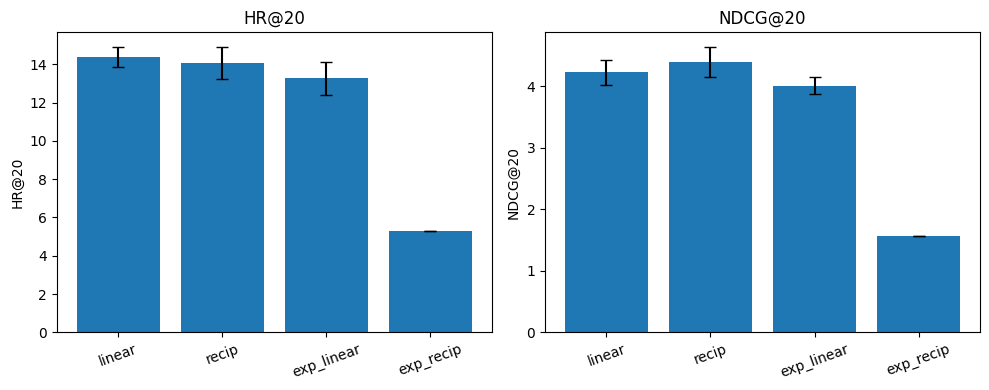

In [9]:
# ═══════════════════════════════════════════════════════════════
# 8. (optional) bar chart of the 4 variants, HR@20 and NDCG@20
# ═══════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, (f"HR@{HIT_K}", f"NDCG@{HIT_K}")):
    sub = summary_df[summary_df["metric"] == metric].set_index("variant").loc[VARIANTS]
    ax.bar(sub.index, sub["mean"], yerr=sub["std"], capsize=4)
    ax.set_title(metric)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("ablation_negweight_barplot.png", dpi=150)
plt.show()
